# Plot mag and JEDI data.

In [1]:
import os
import re
import glob
import time
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator

from JunoPy.index import IndexFile
from JunoPy.mag import MagData
from JunoPy.jedi import JediData
from JunoPy.library import find_ticks_between


## 1. Select the file(s) to plot.

In [2]:
start = dt.datetime.strptime('2019-089T20:35:40', '%Y-%jT%H:%M:%S') - dt.timedelta(minutes=5)
end   = dt.datetime.strptime('2019-089T20:36:36', '%Y-%jT%H:%M:%S') + dt.timedelta(minutes=5)

magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
magdata = MagData(filename=magfile)

print(start.strftime('%Y%j'))

jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))
if not jedifiles:
    jediindex = IndexFile(dataset='jedi')
    jediindex.get_files_between_dates(
        start, end, DoDownload=True, sid='ERSESP')
    
jedidata = []
for jedifile in jedifiles:
    jedidata.append(JediData(filename=jedifile))
    print(jedifile)

2019089
data/jedi/JED_180_LOERSESP_CDR_2019089_V03.TAB
data/jedi/JED_090_LOERSESP_CDR_2019089_V03.TAB


## 2. Plot the data.

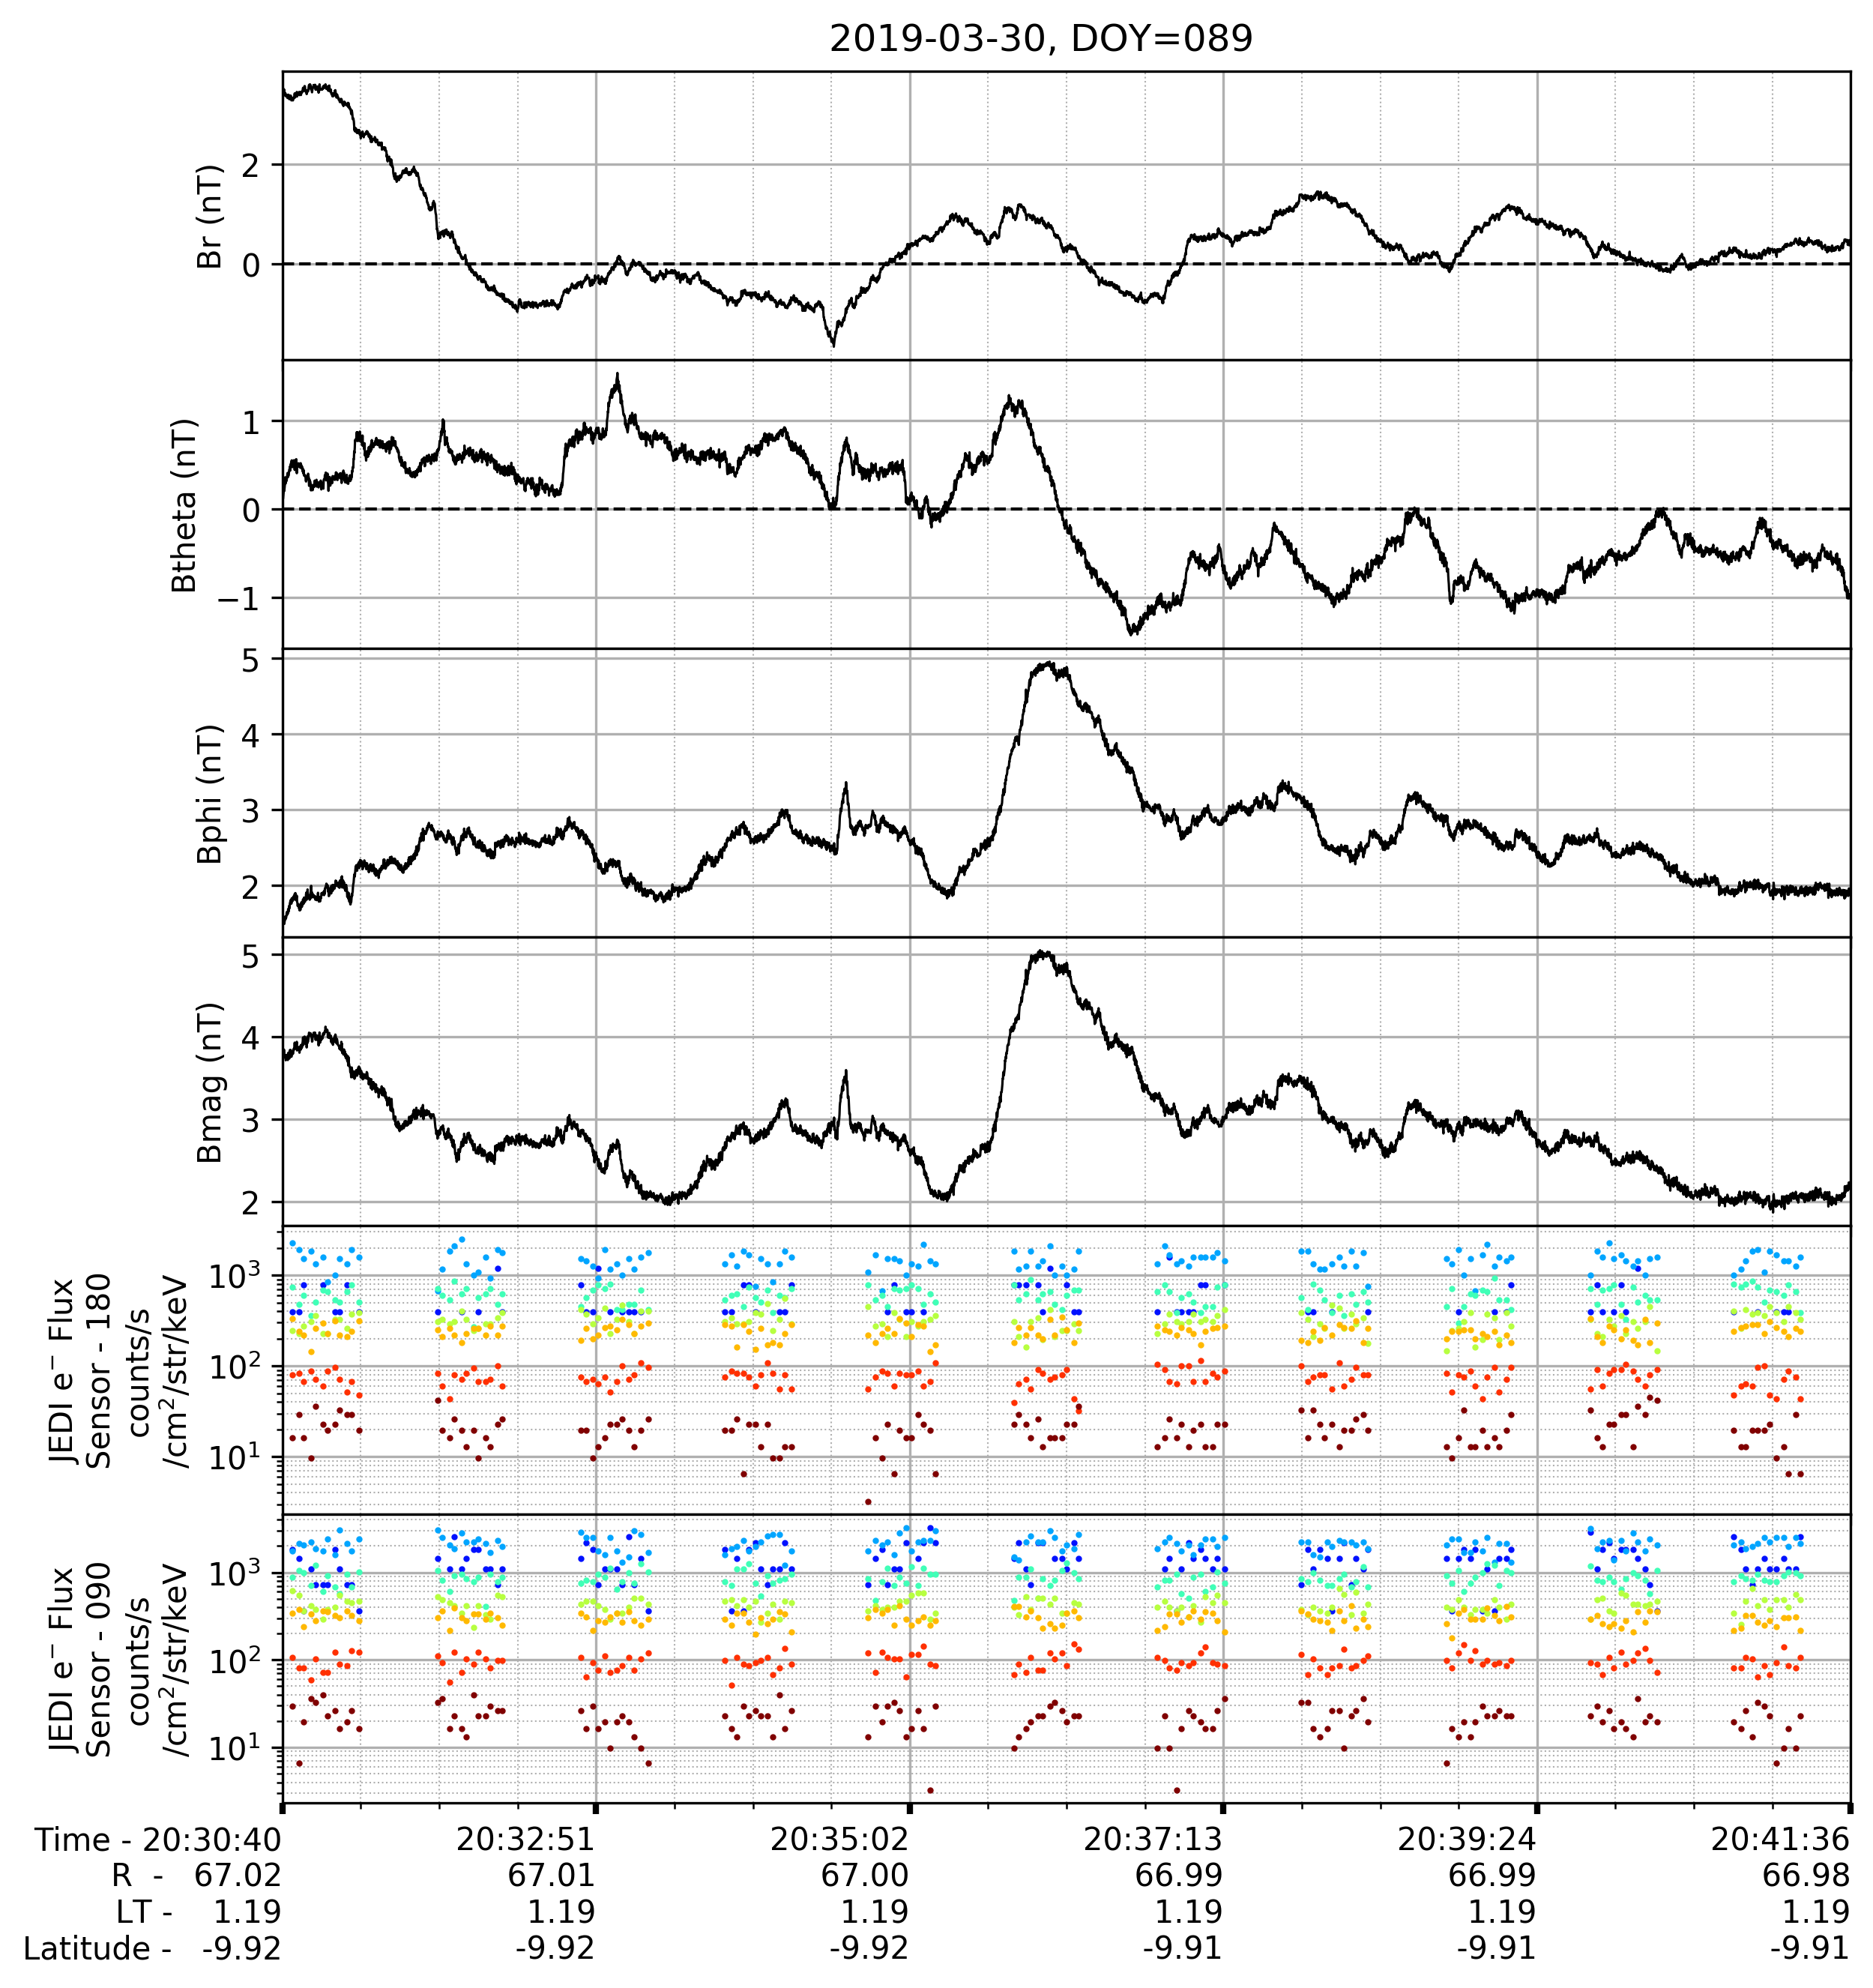

In [3]:
def plot_data(magdata, jedidata, start, end, outfolder=None):
    """Plot data between start and end."""
    
    # Slice the data.
    magdata.df = magdata.df.loc[start:end]
    for jdata in jedidata:
        jdata.df = jdata.df.loc[start:end]
    
    # Find the ticks.
    timearray, tickstring = find_ticks_between(start, end)
    
    # Create the figure.
    fig, axs = plt.subplots(4 + len(jedidata), 1, 
                            gridspec_kw={'hspace': 0, 'right':0.9, 'top':0.9}, 
                            figsize=(9, 11), 
                            dpi=300)
    
    axs[:4] = magdata.plot(vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=axs[:4])
    
    for i, jdata in enumerate(jedidata):
        if 'LO' in jdata.filename:
            axs[4 + i] = jdata.plot_low_res_line_plots(
                axs[4 + i], iTele=0)
        else:
            axs[4 + i] = jdata.plot_flux_spectra(
                axs[4 + i], iTele=0)
        
        
    
    for a in axs:
        # a.set_xlim([timearray[0], timearray[-1]])
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.label_outer()
#         a.axvline(dt.datetime.strptime('2018-085T15:53:45', '%Y-%jT%H:%M:%S'), color='red', lw=0.5)
#         a.axvline(dt.datetime.strptime('2018-085T15:54:15', '%Y-%jT%H:%M:%S'), color='red', lw=0.5)
        
#     for a in axs[:4]:
#         a.axvspan(start + dt.timedelta(minutes=5), 
#                   end - dt.timedelta(minutes=5), alpha=0.2, color=[0.2, 0.2, 0.2])
            
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)
    
    plt.suptitle(dt.datetime.strftime(start, '%Y-%m-%d') + \
                 ', DOY={:s}'.format(dt.datetime.strftime(start, '%j')), y=0.92)
    
    if outfolder:
        fig.savefig(outfolder + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
        plt.close(fig)
    
    fig.savefig('out_mva_temp/' + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
    
    # plt.close(fig)
    
plot_data(magdata, jedidata, start, end)

## 3. Plot all SSD channels

In [ ]:
def plot_data_allssd(magdata, jedidata, start, end):
    """Plot data between start and end."""
    
    # Slice the data.
    magdata.df = magdata.df.loc[start:end]
    for jdata in jedidata:
        jdata.df = jdata.df.loc[start:end]
    
    # Find the ticks.
    timearray, tickstring = find_ticks_between(start, end)
    
    # Create the figure.
    fig, axs = plt.subplots(4 + len(jedidata) * 6, 1, 
                            gridspec_kw={'hspace': 0, 'right':0.9, 'top':0.9}, 
                            figsize=(8.5, 22), 
                            dpi=300)
    
    axs[:4] = magdata.plot(vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=axs[:4])
    
    for i, jdata in enumerate(jedidata):
        if 'LO' in jdata.filename:
            for iTele in range(6):
                axs[4 + i * 6 + iTele] = jdata.plot_low_res_line_plots(
                    axs[4 + i * 6 + iTele], iTele=iTele)
        else:
            for iTele in range(6):
                axs[4 + i * 6 + iTele] = jdata.plot_flux_spectra(
                    axs[4 + i * 6 + iTele], iTele=iTele)
    
    for a in axs:
        # a.set_xlim([timearray[0], timearray[-1]])
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.label_outer()
        
#     for a in axs[:4]:
#         a.axvspan(start + dt.timedelta(minutes=5), 
#                   end - dt.timedelta(minutes=5), alpha=0.2, color=[0.2, 0.2, 0.2])
            
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)
    
    plt.suptitle(dt.datetime.strftime(start, '%Y-%m-%d') + \
                 ', DOY={:s}'.format(dt.datetime.strftime(start, '%j')), y=0.92)
    
    # fig.savefig('out_magdata_4hr/' + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
    # plt.close(fig)
    
# plot_data_allssd(magdata, jedidata, start, end)

## 3. Plot the data for every time duration we have

In [4]:
def read_csv_file():
    start_times = []
    end_times = []
    durations = []
    with open('mva_epochs.csv', 'r') as f:
        f.readline()
        for line in f:
            start_times.append(dt.datetime.strptime(line.split(',')[0], '%Y-%jT%H:%M:%S'))
            end_times.append(dt.datetime.strptime(line.split(',')[1], '%Y-%jT%H:%M:%S'))
            durations.append(float(line.split(',')[2]))
    return start_times, end_times, durations
        
start_times, end_times, durations = read_csv_file()

In [5]:
outfolder = 'out_mva/jedi/'
if not os.path.exists(outfolder):
    os.mkdir(outfolder)
    
for s, e in zip(start_times, end_times):
    
    start = s - dt.timedelta(minutes=5)
    end   = e + dt.timedelta(minutes=5)

    magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
    magdata = MagData(filename=magfile)
    
    try:
        jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))
        jedidata = []
        if not jedifiles:
            jediindex = IndexFile(dataset='jedi')
            jediindex.get_files_between_dates(
                start, end, DoDownload=True, sid='ERSESP')
            jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))

        for jedifile in jedifiles:
            jedidata.append(JediData(filename=jedifile))

        try:
            plot_data(magdata, jedidata, start, end, outfolder=outfolder)
        except KeyError:
            continue
    except:
        continue
        

Date range too short - downloading one file.
Fetching data ... 
Progress bar updates every 5 seconds ...
Date range too short - downloading one file.
Fetching data ... 
Progress bar updates every 5 seconds ...


/Users/sarkango/Envs/JunoPy/lib/python3.7/site-packages/matplotlib/colors.py:1110: RuntimeWarning: invalid value encountered in less_equal
  mask |= resdat <= 0
